# Text Clustering

## 0. Persiapan

Semua pustaka yang dipakai tersedia di Google Colab. Untuk instalasi lokal, jalankan `pip install -r requirements.txt`.

In [1]:
import re
from pathlib import Path
from urllib.request import urlretrieve
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist

from sklearn.cluster import DBSCAN, HDBSCAN, AgglomerativeClustering, KMeans
from sklearn.datasets import make_moons
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer, normalize

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Data: AG News

AG News berisi judul dan ringkasan berita berbahasa Inggris dengan empat label topik: *World*, *Sports*, *Business*, dan *Sci/Tech*. Label **tidak dipakai** saat clustering. Label hanya dipakai di Bagian 8 sebagai pembanding (*gold labels*).

Berkas uji (7.600 berita) diunduh sekali lalu disimpan di folder `data/`. Agar eksperimen cepat, diambil sampel berimbang 500 berita per topik.

Teks mentahnya memuat sisa HTML (misalnya `#39;` dan `quot;`) serta penanda kantor berita seperti `(AP)` dan `(Reuters)`. Fungsi `clean` membuangnya. Tanpa pembersihan ini, K-Means membentuk satu cluster yang isinya ditentukan oleh kantor berita, bukan oleh topik: contoh nyata bahwa cluster mengikuti sinyal apa pun yang paling kuat pada representasi.

In [2]:
URL = "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/test.csv"
DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
path = DATA_DIR / "ag_news_test.csv"
if not path.exists():
    urlretrieve(URL, path)

LABELS = {1: "World", 2: "Sports", 3: "Business", 4: "Sci/Tech"}
raw = pd.read_csv(path, header=None, names=["label_id", "title", "description"])
raw["label"] = raw["label_id"].map(LABELS)

def clean(text):
    text = re.sub(r"&lt;.*?&gt;", " ", text)                       # sisa tag HTML
    text = text.replace("#39;", "'").replace("quot;", '"').replace("amp;", "&").replace("\\", " ")
    text = re.sub(r"\((AP|Reuters|AFP|[A-Za-z. ]*\.com)\)", " ", text)     # penanda kantor berita
    text = re.sub(r"&[a-z]+;|#\d+;", " ", text)
    return re.sub(r"\s+", " ", text).strip()

raw["text"] = (raw["title"] + ". " + raw["description"]).map(clean)
raw["title"] = raw["title"].map(clean)

df = (raw.groupby("label").sample(n=500, random_state=SEED)
         .sample(frac=1, random_state=SEED).reset_index(drop=True))
y_true = df["label"].to_numpy()
print("Ukuran data penuh:", raw.shape, "| ukuran sampel:", df.shape)
df[["label", "text"]].head()

Ukuran data penuh: (7600, 5) | ukuran sampel: (2000, 5)


,label,text
0,World,"Prince Charles chastised for ""old fashioned "" views. A minister has launched a scathing attack on heir to ..."
1,Business,Before-the Bell; Rouse Co. Shares Jump. RSE.N jumped before the bell after General Growth Properties Inc. ...
2,Sports,Bud Selig Has Skin Cancer Surgery. NEW YORK -- Baseball commissioner Bud Selig had surgery Monday to remov...
3,Sci/Tech,Senate Bill Aims at Makers of File-Sharing Software. The Senate Judiciary Committee is considering a copyr...
4,Sports,Sri Lanka batsman fined as Pakistan tie series. Sri Lanka 's Kumar Sangakkara has been fined 30 of his mat...


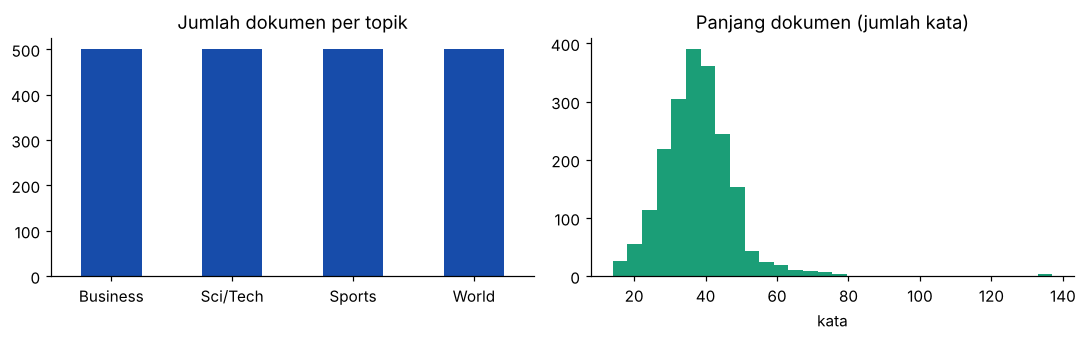

Panjang dokumen: median 37 kata, minimum 14, maksimum 137


In [3]:
n_words = df["text"].str.split().str.len()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
df["label"].value_counts().sort_index().plot.bar(ax=ax[0], color="#174CAA", rot=0)
ax[0].set_title("Jumlah dokumen per topik"); ax[0].set_xlabel("")
ax[1].hist(n_words, bins=30, color="#1B9E77")
ax[1].set_title("Panjang dokumen (jumlah kata)"); ax[1].set_xlabel("kata")
plt.tight_layout(); plt.show()
print(f"Panjang dokumen: median {n_words.median():.0f} kata, minimum {n_words.min()}, maksimum {n_words.max()}")

## 2. Ukuran kemiripan dan jarak

Bagian ini menghitung ulang contoh pada modul, agar rumus dan angka dapat diperiksa sendiri.

### 2.1 Cosine similarity

$$\cos(\mathbf{a},\mathbf{b})=\frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert} \tag{1}$$

**Keterangan:**

- $\mathbf{a}$ = vektor dokumen pertama.
- $\mathbf{b}$ = vektor dokumen kedua.
- $\mathbf{a}\cdot\mathbf{b}$ = hasil kali titik kedua vektor.
- $\lVert\mathbf{a}\rVert$ = panjang (norma Euclidean) vektor dokumen pertama.
- $\lVert\mathbf{b}\rVert$ = panjang (norma Euclidean) vektor dokumen kedua.

In [4]:
def cosine(a, b):
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)))

docs = ["Data is the oil of the digital economy", "Data is a new oil"]
cv = CountVectorizer()                      # token satu huruf seperti "a" tidak dihitung
bow = cv.fit_transform(docs).toarray()
display(pd.DataFrame(bow, columns=cv.get_feature_names_out(), index=["Dok. 1", "Dok. 2"]))

a, b = bow
print("a . b =", a @ b, "| ||a||^2 =", a @ a, "| ||b||^2 =", b @ b)
print("cosine =", round(cosine(a, b), 3))

,data,digital,economy,is,new,of,oil,the
Dok. 1,1,1,1,1,0,1,1,2
Dok. 2,1,0,0,1,1,0,1,0


a . b = 3 | ||a||^2 = 10 | ||b||^2 = 4
cosine = 0.474


### 2.2 Jaccard similarity

$$J(A,B)=\frac{|A\cap B|}{|A\cup B|} \tag{2}$$

**Keterangan:**

- $A$ = himpunan token teks pertama.
- $B$ = himpunan token teks kedua.
- $|A\cap B|$ = banyaknya token yang dimiliki kedua teks.
- $|A\cup B|$ = banyaknya token berbeda pada gabungan kedua teks.

In [5]:
def jaccard(text_a, text_b):
    A, B = set(text_a.lower().split()), set(text_b.lower().split())
    return len(A & B) / len(A | B)

print("Jaccard =", jaccard("the quick brown fox", "the quick fox jumps"))

Jaccard = 0.6


### 2.3 Jarak Euclidean dan hubungannya dengan cosine

$$d(\mathbf{a},\mathbf{b})=\sqrt{\sum_{i=1}^{n}(a_i-b_i)^{2}} \tag{3}$$

**Keterangan:**

- $d(\mathbf{a},\mathbf{b})$ = jarak antara kedua vektor.
- $a_i$ = nilai vektor dokumen pertama pada dimensi $i$.
- $b_i$ = nilai vektor dokumen kedua pada dimensi $i$.
- $n$ = jumlah dimensi.
- $i$ = indeks dimensi.

Untuk vektor yang panjangnya 1, jarak Euclidean dan cosine similarity terhubung langsung:

$$\lVert\mathbf{a}-\mathbf{b}\rVert^{2}=2\left(1-\cos(\mathbf{a},\mathbf{b})\right) \tag{4}$$

**Keterangan:**

- $\lVert\mathbf{a}-\mathbf{b}\rVert$ = jarak Euclidean antara dua vektor satuan.
- $\cos(\mathbf{a},\mathbf{b})$ = cosine similarity kedua vektor.

In [6]:
a = np.array([0.5, 0.6, 0.2, 0.0])
b = np.array([0.4, 0.1, 0.2, 0.3])
print("Jarak Euclidean =", round(float(np.linalg.norm(a - b)), 3))

# Persamaan 4: periksa pada 1.000 pasang vektor acak yang dinormalisasi L2
U = normalize(rng.normal(size=(1000, 50)))
V = normalize(rng.normal(size=(1000, 50)))
lhs = ((U - V) ** 2).sum(axis=1)
rhs = 2 * (1 - (U * V).sum(axis=1))
print("Selisih terbesar antara ruas kiri dan kanan Persamaan 4:", float(np.abs(lhs - rhs).max()))

Jarak Euclidean = 0.592
Selisih terbesar antara ruas kiri dan kanan Persamaan 4: 8.881784197001252e-16


Selisihnya hanya sebesar galat pembulatan. Artinya, setelah normalisasi L2, algoritma berbasis jarak Euclidean (seperti K-Means) mengurutkan tetangga persis seperti cosine similarity.

## 3. Representasi sparse: TF-IDF

TF-IDF dibangun dengan unigram dan bigram. Nama kantor berita dan beberapa kata yang muncul di hampir semua berita ditambahkan ke daftar *stopword*. `TfidfVectorizer` menormalisasi setiap baris dengan L2 secara bawaan, sehingga Persamaan 4 langsung berlaku.

In [7]:
STOP_EN = sorted(ENGLISH_STOP_WORDS | {"ap", "reuters", "afp", "said", "says", "new"})
tfidf = TfidfVectorizer(stop_words=STOP_EN, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(df["text"])
terms = tfidf.get_feature_names_out()

n_docs, n_feat = X_tfidf.shape
sparsity = 1 - X_tfidf.nnz / (n_docs * n_feat)
print(f"Matriks TF-IDF: {n_docs} dokumen x {n_feat} fitur")
print(f"Sparsity: {sparsity:.2%} sel bernilai nol | rata-rata {X_tfidf.nnz / n_docs:.1f} fitur tak nol per dokumen")
print("Norma baris (lima pertama):", np.round(np.sqrt(X_tfidf.multiply(X_tfidf).sum(axis=1)).A1[:5], 3))

Matriks TF-IDF: 2000 dokumen x 7237 fitur
Sparsity: 99.72% sel bernilai nol | rata-rata 20.2 fitur tak nol per dokumen
Norma baris (lima pertama): [1. 1. 1. 1. 1.]


### Konsentrasi jarak

Pada dimensi tinggi, tetangga terdekat dan terjauh menjadi hampir sama jauhnya. Simulasi berikut mengukur *kontras relatif*, yaitu (jarak terjauh - jarak terdekat) / jarak terdekat, untuk 500 titik acak seragam.

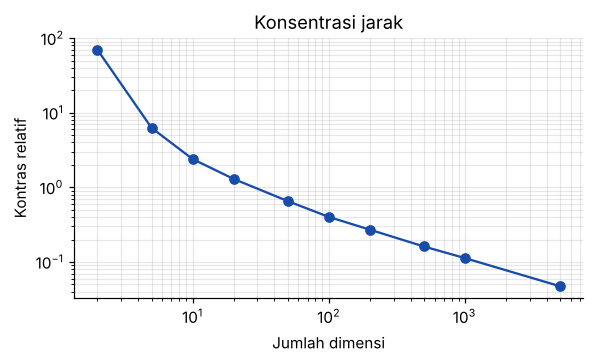

{2: 70.0, 5: 6.27, 10: 2.4, 20: 1.3, 50: 0.65, 100: 0.4, 200: 0.27, 500: 0.16, 1000: 0.11, 5000: 0.05}


In [8]:
dims = [2, 5, 10, 20, 50, 100, 200, 500, 1000, 5000]
contrast = []
for d in dims:
    vals = []
    for _ in range(30):
        pts, q = rng.random((500, d)), rng.random(d)
        dist = np.linalg.norm(pts - q, axis=1)
        vals.append((dist.max() - dist.min()) / dist.min())
    contrast.append(np.mean(vals))

plt.figure(figsize=(5.5, 3.4))
plt.loglog(dims, contrast, "-o", color="#174CAA")
plt.xlabel("Jumlah dimensi"); plt.ylabel("Kontras relatif"); plt.grid(alpha=.3, which="both")
plt.title("Konsentrasi jarak"); plt.tight_layout(); plt.show()
print({d: round(float(c), 2) for d, c in zip(dims, contrast)})

## 4. Reduksi dimensi

Matriks TF-IDF direduksi dengan **Truncated SVD** (LSA) ke 100 dimensi, lalu dinormalisasi L2 kembali. PCA tidak dipakai karena pemusatan data akan menghilangkan sifat sparse.

In [9]:
svd = TruncatedSVD(n_components=100, random_state=SEED)
lsa = make_pipeline(svd, Normalizer(copy=False))
X_lsa = lsa.fit_transform(X_tfidf)
print("Bentuk setelah reduksi:", X_lsa.shape)
print(f"Variansi yang dijelaskan 100 komponen: {svd.explained_variance_ratio_.sum():.1%}")

Bentuk setelah reduksi: (2000, 100)
Variansi yang dijelaskan 100 komponen: 16.8%


Untuk melihat datanya, vektor LSA diproyeksikan ke 2D dengan t-SNE. Plot ini **hanya untuk visualisasi**: ukuran cluster dan jarak antar-cluster pada plot t-SNE tidak bermakna, dan keluarannya tidak dipakai sebagai masukan clustering. Warna menunjukkan label topik asli.

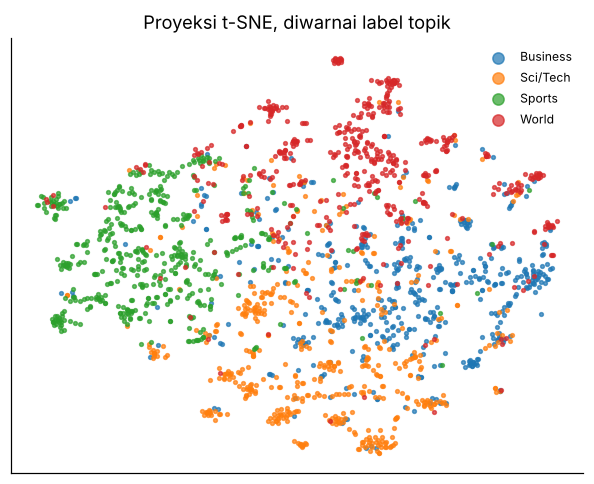

In [10]:
X_2d = TSNE(n_components=2, metric="cosine", init="random", perplexity=30, random_state=SEED).fit_transform(X_lsa)

def scatter(labels, title, ax):
    for lab in sorted(set(labels), key=str):
        m = np.asarray(labels) == lab
        ax.scatter(X_2d[m, 0], X_2d[m, 1], s=6, alpha=.7, label=str(lab), color="lightgray" if lab == -1 else None)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    ax.legend(markerscale=3, fontsize=8, frameon=False)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
scatter(y_true, "Proyeksi t-SNE, diwarnai label topik", ax)
plt.tight_layout(); plt.show()

## 5. K-Means

K-Means meminimalkan jumlah kuadrat jarak setiap dokumen ke *centroid* clusternya:

$$J=\sum_{k=1}^{K}\;\sum_{\mathbf{x}_i\in C_k}\lVert\mathbf{x}_i-\boldsymbol{\mu}_k\rVert^{2} \tag{5}$$

**Keterangan:**

- $J$ = jumlah kuadrat jarak dalam cluster (*inertia*).
- $K$ = jumlah cluster, ditentukan sebelum algoritma dijalankan.
- $C_k$ = himpunan dokumen pada cluster ke-$k$.
- $\mathbf{x}_i$ = vektor dokumen ke-$i$.
- $\boldsymbol{\mu}_k$ = centroid (vektor rata-rata) cluster ke-$k$.
- $k$ = indeks cluster.
- $i$ = indeks dokumen.

Karena vektor LSA sudah dinormalisasi L2, K-Means di sini berperilaku seperti *spherical K-Means*.

In [11]:
km = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=SEED).fit(X_lsa)
labels_km = km.labels_
print("Inertia:", round(km.inertia_, 1), "| ukuran cluster:", np.bincount(labels_km))

def top_terms(labels, X=X_tfidf, vocab=terms, n=10):
    # term dengan rata-rata bobot TF-IDF tertinggi pada tiap cluster
    rows = {}
    for c in sorted(set(labels) - {-1}):
        mean_w = np.asarray(X[np.asarray(labels) == c].mean(axis=0)).ravel()
        rows[f"cluster {c}"] = ", ".join(vocab[mean_w.argsort()[::-1][:n]])
    return pd.Series(rows, name="term teratas").to_frame()

top_terms(labels_km)

Inertia: 1837.4 | ukuran cluster: [670 716 528  86]


,term teratas
cluster 0,"iraq, president, bush, people, minister, baghdad, killed, friday, say, troops"
cluster 1,"company, microsoft, internet, corp, year, software, market, business, billion, percent"
cluster 2,"game, season, team, win, league, sunday, coach, day, victory, night"
cluster 3,"oil, prices, oil prices, crude, crude oil, stocks, yukos, barrel, opec, energy"


In [12]:
# Tabel silang: cluster (baris) terhadap label topik (kolom). Label hanya dipakai untuk memeriksa hasil.
pd.crosstab(pd.Series(labels_km, name="cluster"), pd.Series(y_true, name="label"))

label,Business,Sci/Tech,Sports,World
cluster,,,,
0,75,118,30,447
1,340,355,4,17
2,12,26,465,25
3,73,1,1,11


Pada hasil yang tersimpan di notebook ini, K-Means tidak menemukan kembali keempat topik. Berita *Business* dan *Sci/Tech* sebagian besar masuk ke cluster yang sama, sedangkan berita tentang harga minyak membentuk cluster kecil tersendiri. Pengelompokan itu masuk akal dari sisi kosakata, walaupun berbeda dari label redaksi.

### Menentukan jumlah cluster

Metode *elbow* mencari titik siku pada kurva inertia. Analisis *silhouette* memilih $K$ dengan rata-rata silhouette tertinggi (di sini dihitung dengan jarak cosine).

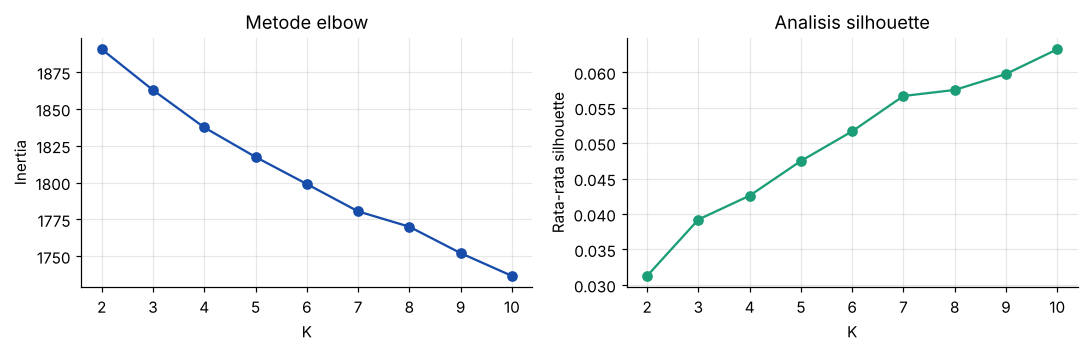

Silhouette per K: {2: 0.031, 3: 0.039, 4: 0.043, 5: 0.047, 6: 0.052, 7: 0.057, 8: 0.058, 9: 0.06, 10: 0.063}
K dengan silhouette tertinggi: 10


In [13]:
Ks = range(2, 11)
inertias, sils = [], []
for k in Ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_lsa)
    inertias.append(m.inertia_)
    sils.append(silhouette_score(X_lsa, m.labels_, metric="cosine"))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].plot(Ks, inertias, "-o", color="#174CAA"); ax[0].set_title("Metode elbow"); ax[0].set_xlabel("K"); ax[0].set_ylabel("Inertia")
ax[1].plot(Ks, sils, "-o", color="#1B9E77"); ax[1].set_title("Analisis silhouette"); ax[1].set_xlabel("K"); ax[1].set_ylabel("Rata-rata silhouette")
for a_ in ax: a_.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("Silhouette per K:", {k: round(float(s), 3) for k, s in zip(Ks, sils)})
print("K dengan silhouette tertinggi:", list(Ks)[int(np.argmax(sils))])

**Yang perlu diperhatikan.** Pada teks nyata, kurva inertia turun mulus tanpa siku yang jelas, dan nilai silhouette rendah untuk semua $K$. Ini berbeda dari data sintetis pada slide. Kedua kriteria adalah petunjuk, bukan bukti: pilihan $K$ juga perlu mempertimbangkan apakah cluster dapat ditafsirkan dan apakah kerinciannya sesuai tujuan analisis.

## 6. Hierarchical clustering

*Agglomerative clustering* menggabungkan dua cluster terdekat secara berulang. Kriteria *linkage* menentukan arti "terdekat". Ward hanya berlaku untuk jarak Euclidean, sedangkan tiga linkage lain dijalankan dengan jarak cosine.

In [14]:
configs = {"ward (euclidean)": dict(linkage="ward"),
           "complete (cosine)": dict(linkage="complete", metric="cosine"),
           "average (cosine)": dict(linkage="average", metric="cosine"),
           "single (cosine)": dict(linkage="single", metric="cosine")}
agg_labels, rows = {}, []
for name, kw in configs.items():
    lab = AgglomerativeClustering(n_clusters=4, **kw).fit_predict(X_lsa)
    agg_labels[name] = lab
    rows.append({"linkage": name, "ukuran cluster": sorted(np.bincount(lab), reverse=True),
                 "ARI terhadap label": round(adjusted_rand_score(y_true, lab), 3)})
pd.DataFrame(rows).set_index("linkage")

,ukuran cluster,ARI terhadap label
linkage,,
ward (euclidean),"[1354, 453, 144, 49]",0.161
complete (cosine),"[725, 545, 402, 328]",0.008
average (cosine),"[967, 526, 426, 81]",0.344
single (cosine),"[1997, 1, 1, 1]",-0.000


Kolom ukuran cluster memperlihatkan perilaku tiap linkage. *Single linkage* cenderung membentuk satu rantai raksasa dan beberapa cluster berisi sangat sedikit dokumen. Linkage lain menghasilkan pembagian yang lebih berimbang.

Dendrogram berikut dibuat dari sampel 40 dokumen (10 per topik) agar terbaca. Label daun adalah topik asli.

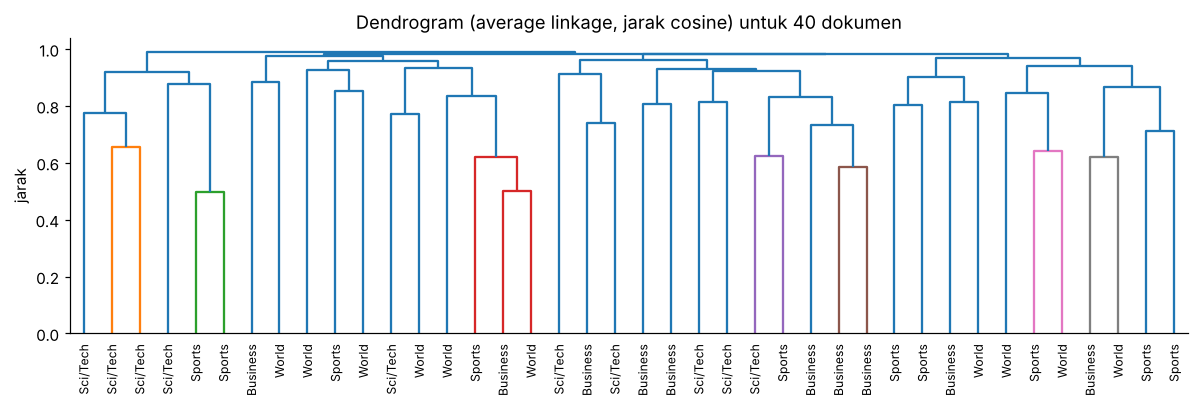

In [15]:
sample = df.groupby("label").sample(n=10, random_state=1).index.to_numpy()
Z = linkage(pdist(X_lsa[sample], metric="cosine"), method="average")
plt.figure(figsize=(11, 3.8))
dendrogram(Z, labels=y_true[sample], leaf_rotation=90, leaf_font_size=8, color_threshold=0.7 * Z[:, 2].max())
plt.title("Dendrogram (average linkage, jarak cosine) untuk 40 dokumen"); plt.ylabel("jarak")
plt.tight_layout(); plt.show()

## 7. DBSCAN dan HDBSCAN

DBSCAN memerlukan satu radius global `eps`. Sel berikut mencoba beberapa nilai `eps` (jarak cosine, `min_samples=10`) pada vektor LSA 100 dimensi dan mencatat jumlah cluster serta porsi *noise*.

In [16]:
rows = []
for eps in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    lab = DBSCAN(eps=eps, min_samples=10, metric="cosine").fit_predict(X_lsa)
    rows.append({"eps": eps, "jumlah cluster": len(set(lab) - {-1}), "porsi noise": f"{(lab == -1).mean():.1%}",
                 "cluster terbesar": int(np.bincount(lab[lab >= 0]).max()) if (lab >= 0).any() else 0})
pd.DataFrame(rows).set_index("eps")

,jumlah cluster,porsi noise,cluster terbesar
eps,,,
0.3,20,85.2%,31
0.4,36,56.8%,64
0.5,3,17.2%,1641
0.6,1,0.1%,1998
0.7,1,0.0%,2000
0.8,1,0.0%,2000


Tabel di atas memperlihatkan kelemahan radius global pada teks berdimensi tinggi: nilai `eps` yang kecil membuang hampir semua dokumen sebagai noise, sedangkan nilai yang besar melebur dokumen ke dalam satu cluster raksasa. Rentang `eps` yang memberi beberapa cluster bermakna sangat sempit, atau tidak ada.

HDBSCAN tidak memerlukan `eps`. Algoritma ini dijalankan pada dua ruang: LSA 100 dimensi dan LSA 10 dimensi, untuk melihat pengaruh reduksi dimensi.

In [17]:
X_lsa10 = make_pipeline(TruncatedSVD(n_components=10, random_state=SEED), Normalizer(copy=False)).fit_transform(X_tfidf)

hdb_labels, rows = {}, []
for name, X in {"HDBSCAN pada LSA-100": X_lsa, "HDBSCAN pada LSA-10": X_lsa10}.items():
    lab = HDBSCAN(min_cluster_size=25, min_samples=5).fit_predict(X)
    hdb_labels[name] = lab
    rows.append({"konfigurasi": name, "jumlah cluster": len(set(lab) - {-1}), "porsi noise": f"{(lab == -1).mean():.1%}",
                 "ukuran cluster": sorted(np.bincount(lab[lab >= 0]), reverse=True) if (lab >= 0).any() else []})
pd.DataFrame(rows).set_index("konfigurasi")

,jumlah cluster,porsi noise,ukuran cluster
konfigurasi,,,
HDBSCAN pada LSA-100,14,67.3%,"[122, 65, 58, 56, 46, 44, 40, 39, 36, 34, 33, 30, 25, 25]"
HDBSCAN pada LSA-10,7,46.9%,"[441, 262, 109, 69, 68, 61, 51]"


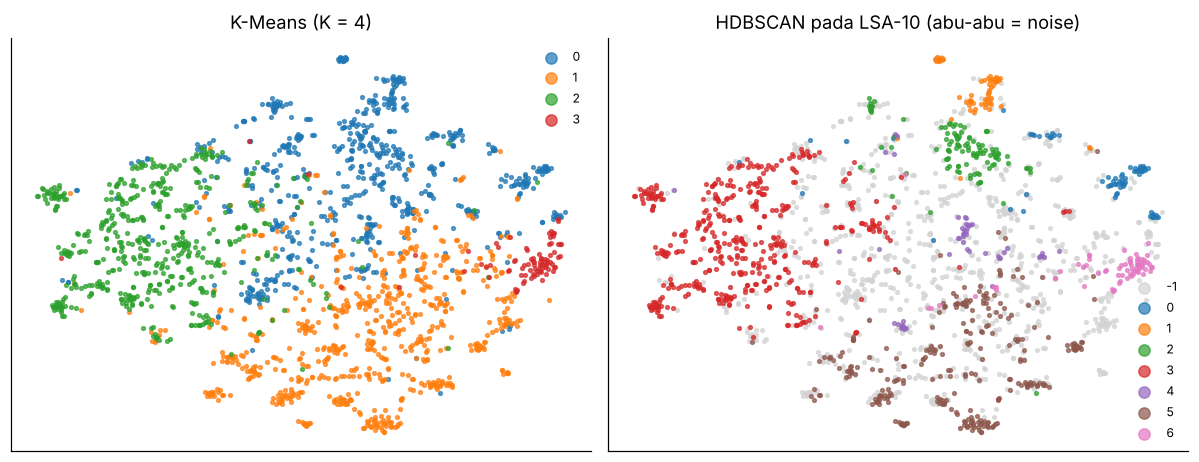

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
scatter(labels_km, "K-Means (K = 4)", ax[0])
scatter(hdb_labels["HDBSCAN pada LSA-10"], "HDBSCAN pada LSA-10 (abu-abu = noise)", ax[1])
plt.tight_layout(); plt.show()

Porsi noise harus selalu dilaporkan bersama hasil HDBSCAN. Dokumen yang diberi label noise tidak ikut dinilai oleh metrik, sehingga skor dapat tampak lebih baik daripada kenyataannya. Hal ini dibahas lagi pada Bagian 8.

## 8. Evaluasi

### 8.1 Metrik internal dan eksternal

Silhouette untuk satu dokumen:

$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),\,b(i)\}} \tag{6}$$

**Keterangan:**

- $s(i)$ = nilai silhouette dokumen ke-$i$, antara -1 dan 1.
- $a(i)$ = rata-rata jarak dokumen ke-$i$ ke dokumen lain dalam clusternya sendiri.
- $b(i)$ = rata-rata jarak dokumen ke-$i$ ke dokumen pada cluster lain yang terdekat.
- $i$ = indeks dokumen.

Purity terhadap label emas:

$$\mathrm{Purity}=\frac{1}{N}\sum_{k=1}^{K}\max_{j}\,|C_k\cap L_j| \tag{7}$$

**Keterangan:**

- $\mathrm{Purity}$ = proporsi dokumen yang sesuai dengan label mayoritas clusternya.
- $N$ = jumlah seluruh dokumen.
- $K$ = jumlah cluster.
- $C_k$ = himpunan dokumen pada cluster ke-$k$.
- $L_j$ = himpunan dokumen dengan label emas ke-$j$.
- $k$ = indeks cluster.
- $j$ = indeks label emas.

Fungsi `evaluate` menghitung metrik hanya pada dokumen yang mendapat cluster, lalu melaporkan **cakupan**, yaitu porsi dokumen yang bukan noise. Semua metrik internal dihitung pada ruang yang sama (LSA 100 dimensi) agar dapat dibandingkan.

In [19]:
def purity(y, labels):
    ct = pd.crosstab(pd.Series(labels), pd.Series(y))
    return ct.max(axis=1).sum() / ct.values.sum()

def evaluate(name, labels, X=X_lsa, y=y_true):
    labels = np.asarray(labels); keep = labels != -1
    n_clusters = len(set(labels[keep]))
    row = {"pipeline": name, "cluster": n_clusters, "cakupan": keep.mean()}
    if n_clusters >= 2:
        row.update({"silhouette": silhouette_score(X[keep], labels[keep], metric="cosine"),
                    "Davies-Bouldin": davies_bouldin_score(X[keep], labels[keep]),
                    "Calinski-Harabasz": calinski_harabasz_score(X[keep], labels[keep]),
                    "purity": purity(y[keep], labels[keep]),
                    "ARI": adjusted_rand_score(y[keep], labels[keep]),
                    "NMI": normalized_mutual_info_score(y[keep], labels[keep])})
    return row

labels_km_tfidf = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(X_tfidf)
results = pd.DataFrame([
    evaluate("K-Means pada TF-IDF", labels_km_tfidf),
    evaluate("K-Means pada LSA-100", labels_km),
    evaluate("Agglomerative, Ward", agg_labels["ward (euclidean)"]),
    evaluate("Agglomerative, average cosine", agg_labels["average (cosine)"]),
    evaluate("HDBSCAN pada LSA-100", hdb_labels["HDBSCAN pada LSA-100"]),
    evaluate("HDBSCAN pada LSA-10", hdb_labels["HDBSCAN pada LSA-10"]),
]).set_index("pipeline")
results.round(3)

,cluster,cakupan,silhouette,Davies-Bouldin,Calinski-Harabasz,purity,ARI,NMI
pipeline,,,,,,,,
K-Means pada TF-IDF,4,1.000,0.028,5.053,25.083,0.478,0.093,0.261
K-Means pada LSA-100,4,1.000,0.043,5.758,30.790,0.670,0.459,0.476
"Agglomerative, Ward",4,1.000,0.023,5.537,23.388,0.502,0.161,0.281
"Agglomerative, average cosine",4,1.000,0.027,6.331,21.839,0.616,0.344,0.366
HDBSCAN pada LSA-100,14,0.326,0.212,2.799,17.071,0.809,0.251,0.486
HDBSCAN pada LSA-10,7,0.530,0.101,3.704,22.054,0.840,0.634,0.603


**Cara membaca tabel.** Pada hasil yang tersimpan di notebook ini, kedua konfigurasi HDBSCAN memperoleh silhouette dan purity tertinggi, tetapi cakupannya hanya sekitar sepertiga sampai setengah dokumen. Skor tersebut diperoleh dengan mengesampingkan dokumen yang sulit. Bandingkan juga urutan pipeline menurut metrik internal (silhouette, Davies-Bouldin, Calinski-Harabasz) dengan urutan menurut metrik eksternal (purity, ARI, NMI). Keduanya tidak selalu sejalan. Perhatikan juga kolom cakupan: skor pipeline yang cakupannya jauh di bawah 1 hanya menggambarkan sebagian dokumen, sehingga tidak dapat dibandingkan langsung dengan pipeline yang menugaskan semua dokumen.

### 8.2 Ketika metrik menyesatkan

Pada data dua bulan sabit, K-Means memotong kedua kelompok secara salah tetapi memperoleh silhouette lebih tinggi daripada DBSCAN yang menemukan kelompok sebenarnya.

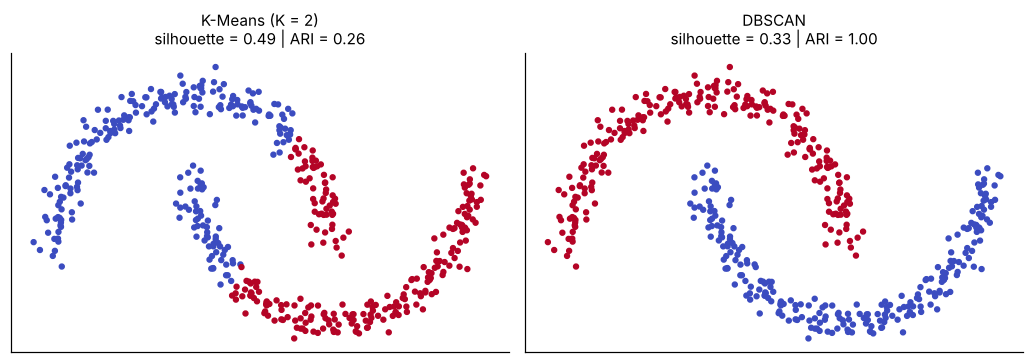

In [20]:
Xm, ym = make_moons(n_samples=500, noise=0.06, random_state=1)
moon = {"K-Means (K = 2)": KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(Xm),
        "DBSCAN": DBSCAN(eps=0.2, min_samples=5).fit_predict(Xm)}
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
for a_, (name, lab) in zip(ax, moon.items()):
    a_.scatter(Xm[:, 0], Xm[:, 1], c=lab, s=10, cmap="coolwarm")
    a_.set_title(f"{name}\nsilhouette = {silhouette_score(Xm, lab):.2f} | ARI = {adjusted_rand_score(ym, lab):.2f}", fontsize=10)
    a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()

Metrik internal menghargai geometri yang diasumsikan algoritma (cluster kompak dan konveks). Skor tinggi tidak menjamin cluster bermakna.

### 8.3 Kestabilan

K-Means hanya menemukan minimum lokal, sehingga hasilnya bergantung pada inisialisasi. Sel berikut menjalankan K-Means sepuluh kali dengan *seed* berbeda (`n_init=1`) dan mengukur kesesuaian antar-hasil dengan ARI berpasangan.

In [21]:
runs = [KMeans(n_clusters=4, n_init=1, random_state=s).fit_predict(X_lsa) for s in range(10)]
pair = [adjusted_rand_score(runs[i], runs[j]) for i in range(10) for j in range(i + 1, 10)]
ari_gold = [adjusted_rand_score(y_true, r) for r in runs]
print(f"ARI antar-percobaan : rata-rata {np.mean(pair):.3f}, minimum {np.min(pair):.3f}, maksimum {np.max(pair):.3f}")
print(f"ARI terhadap label  : rata-rata {np.mean(ari_gold):.3f}, minimum {np.min(ari_gold):.3f}, maksimum {np.max(ari_gold):.3f}")

ARI antar-percobaan : rata-rata 0.610, minimum 0.287, maksimum 0.950
ARI terhadap label  : rata-rata 0.517, minimum 0.293, maksimum 0.599


Jika ARI antar-percobaan jauh di bawah 1, satu kali percobaan tidak cukup untuk menarik kesimpulan. Itulah alasan `n_init` lebih dari satu dipakai pada bagian sebelumnya, dan alasan kestabilan perlu dilaporkan bersama metrik lain.

## 9. Interpretasi cluster

Nomor cluster tidak bermakna sampai isinya dibaca. Dua sumber bukti dipakai di sini:

- **term pembeda** dengan *class-based* TF-IDF (c-TF-IDF): semua dokumen dalam satu cluster digabung menjadi satu dokumen besar, lalu dicari term yang sering muncul di cluster itu dan jarang di cluster lain;
- **dokumen representatif**, yaitu dokumen yang paling dekat dengan centroid.

Keduanya diterapkan pada hasil K-Means dari Bagian 5.

In [22]:
def c_tf_idf(texts, labels, n=10):
    labels = np.asarray(labels)
    classes = sorted(set(labels) - {-1})
    joined = [" ".join(np.asarray(texts)[labels == c]) for c in classes]
    cvec = CountVectorizer(stop_words=STOP_EN, ngram_range=(1, 2), min_df=1)
    counts = cvec.fit_transform(joined).toarray().astype(float)
    tf = counts / counts.sum(axis=1, keepdims=True)                 # frekuensi term di dalam cluster
    idf = np.log(1 + counts.sum(axis=1).mean() / counts.sum(axis=0))  # term yang jarang di cluster lain diberi bobot lebih
    vocab = cvec.get_feature_names_out()
    return pd.Series({f"cluster {c}": ", ".join(vocab[(tf[i] * idf).argsort()[::-1][:n]]) for i, c in enumerate(classes)},
                     name="term c-TF-IDF").to_frame()

c_tf_idf(df["text"], labels_km)

,term c-TF-IDF
cluster 0,"iraq, president, bush, people, minister, baghdad, killed, friday, thursday, troops"
cluster 1,"company, microsoft, year, internet, corp, percent, software, market, billion, computer"
cluster 2,"game, season, team, win, league, sunday, victory, day, night, coach"
cluster 3,"oil, prices, oil prices, crude, crude oil, stocks, yukos, barrel, opec, record"


In [23]:
sim = cosine_similarity(X_lsa, km.cluster_centers_)
for c in range(4):
    members = np.where(labels_km == c)[0]
    best = members[sim[members, c].argsort()[::-1][:3]]
    print(f"Cluster {c} ({len(members)} dokumen)")
    for i in best:
        print("  -", df.loc[i, "title"])
    print()

Cluster 0 (670 dokumen)
  - Fierce fighting in Iraq
  - U.S. Alerts Schools About Terror Threat
  - Thai PM to Address Nation as More Bombs Hit South

Cluster 1 (716 dokumen)
  - Shake-up at British retailer
  - Aether Declines Higher Bid for Unit
  - Microsoft closes Hotmail to Outlook and Outlook Express users

Cluster 2 (528 dokumen)
  - GAME DAY RECAP Sunday, November 28
  - Newcastle held to draw by Charlton
  - Belmont beats the best to take its place at the top

Cluster 3 (86 dokumen)
  - The Next Shock: Not Oil, but Debt
  - Oil Prices Slip, Winter Supplies Seen Up
  - Will High Oil Prices Lead to Recession?



Berdasarkan term pembeda dan dokumen representatif, setiap cluster dapat diberi nama. Nama itu baru dapat diterima setelah sampel dokumen lain dalam cluster yang sama dibaca dan ternyata sesuai. Sel berikut mengambil lima dokumen acak dari satu cluster untuk pemeriksaan tersebut.

In [24]:
cluster_id = 0
df.loc[labels_km == cluster_id, ["label", "title"]].sample(5, random_state=SEED)

,label,title
1053,World,Costa Rica quake
425,World,E. Guinea coup suspects say they were tortured
1450,World,Karzai Travels North on First Domestic Trip Since Rocket Attack
1895,World,N. Korea and U.S. Met Twice This Week
760,World,Chavez Visit to Spain Sparks Coup Controversy


## 10. Data berbahasa Indonesia

Pipeline yang sama dijalankan pada SmSA (IndoNLU), yaitu ulasan dan komentar berbahasa Indonesia dengan label **sentimen** (positif, netral, negatif). Tujuannya adalah melihat apakah cluster yang terbentuk mengikuti label tersebut.

scikit-learn tidak menyediakan daftar *stopword* bahasa Indonesia, sehingga dipakai daftar pendek buatan sendiri dan `max_df` untuk membuang kata yang terlalu umum.

In [25]:
URL_ID = "https://raw.githubusercontent.com/IndoNLP/indonlu/master/dataset/smsa_doc-sentiment-prosa/train_preprocess.tsv"
path_id = DATA_DIR / "smsa_train.tsv"
if not path_id.exists():
    urlretrieve(URL_ID, path_id)

smsa = pd.read_csv(path_id, sep="\t", header=None, names=["text", "sentiment"], quoting=3)
smsa = smsa.sample(n=2000, random_state=SEED).reset_index(drop=True)
print(smsa["sentiment"].value_counts().to_dict())

STOP_ID = ["yang", "dan", "di", "ke", "dari", "ini", "itu", "untuk", "dengan", "pada", "adalah", "juga", "saya", "kami", "kita",
           "anda", "nya", "ada", "tidak", "akan", "atau", "karena", "sudah", "bisa", "sangat", "lebih", "saja", "kalau", "jadi",
           "oleh", "dalam", "sebagai", "tapi", "banyak", "seperti", "aku", "ya", "sih", "nih", "pun", "lagi", "buat", "sama",
           "mereka", "dia", "ia", "se", "para", "hanya", "masih", "bagi", "telah", "agar", "yg", "ga", "gak", "tak", "enggak"]
tfidf_id = TfidfVectorizer(stop_words=STOP_ID, ngram_range=(1, 2), min_df=3, max_df=0.4, sublinear_tf=True)
Xi_tfidf = tfidf_id.fit_transform(smsa["text"])
Xi = make_pipeline(TruncatedSVD(n_components=100, random_state=SEED), Normalizer(copy=False)).fit_transform(Xi_tfidf)

km_id = KMeans(n_clusters=6, n_init=10, random_state=SEED).fit(Xi)
print("Matriks TF-IDF:", Xi_tfidf.shape, "| ukuran cluster:", np.bincount(km_id.labels_))
top_terms(km_id.labels_, X=Xi_tfidf, vocab=tfidf_id.get_feature_names_out(), n=8)

{'positive': 1177, 'negative': 610, 'neutral': 213}


Matriks TF-IDF: (2000, 3412) | ukuran cluster: [375 409 570 324 238  84]


,term teratas
cluster 0,"enak, ayam, goreng, menu, rasanya, harga, makan, nasi"
cluster 1,"makanan, enak, tempat, sini, nyaman, makan, harga, banget"
cluster 2,"banget, marah, mau, indosat, pakai, produk, suka, apa"
cluster 3,"tempat, bandung, makanan, cukup, kota, jalan, makan, restoran"
cluster 4,"jokowi, pak, presiden, demokrat, partai, prabowo, 2018, jangan"
cluster 5,"orang, orang orang, tni, pejabat, indonesia, semua, orang lain, sesat"


In [26]:
ct = pd.crosstab(pd.Series(km_id.labels_, name="cluster"), smsa["sentiment"])
display(ct)
print("ARI terhadap label sentimen:", round(adjusted_rand_score(smsa["sentiment"], km_id.labels_), 3))
print("Purity terhadap label sentimen:", round(purity(smsa["sentiment"].to_numpy(), km_id.labels_), 3))

sentiment,negative,neutral,positive
cluster,,,
0,39,2,334
1,56,0,353
2,324,108,138
3,22,6,296
4,98,91,49
5,71,6,7


ARI terhadap label sentimen: 0.136
Purity terhadap label sentimen: 0.738


**Yang perlu diperhatikan.** Bandingkan term teratas tiap cluster dengan tabel silang di atas. Cluster terbentuk terutama menurut **apa yang dibicarakan**, sedangkan label emas pada data ini menggambarkan **sentimen**. Nilai ARI yang rendah terhadap label sentimen tidak berarti clustering gagal: label emas hanya mewakili satu dari beberapa pengelompokan yang sah. Inilah alasan metrik eksternal harus dibaca bersama tujuan analisis.

## Penutup

Bahan eksplorasi lanjutan:

- ganti `n_components` pada Truncated SVD (misalnya 20, 50, 300) dan amati perubahan pada tabel evaluasi;
- ganti `ngram_range` dan `min_df` pada TF-IDF, lalu periksa kembali term teratas tiap cluster;
- jalankan K-Means dengan $K$ yang lebih besar dari 4 dan nilai apakah cluster tambahan masih dapat ditafsirkan;
- ulangi Bagian 10 dengan korpus sendiri.